# Step 10: Per-batch drift analysis with confidence intervals

**Goal:** find out how much accuracy falls as batches get further from the training data, which model resists drift
best, and which differences between models are real and not just noise.

**Models analysed** (all trained on batches 1-3 only, tested on batches 4-10; chosen by rule, not by test results):
- the 7 tuned model families, each with the reduction (none / PCA / LDA) that had the best Step 8 *validation* score;
- the stack and the soft vote from Step 9;
- the untuned SVM, to ask whether tuning made a real difference.

**Method**
- The saved models from Steps 8 and 9 make the predictions; the notebook first checks that they reproduce the earlier
  results exactly.
- **Bootstrap 95% confidence intervals** (2,000 resamples, seed 42): each test batch is resampled separately, and the
  *same* resampled rows are used for every model, so differences between models are paired.
- **Caveat:** rows within a batch were recorded close together in time and are not independent, so these intervals are
  *narrower than the true uncertainty*. Treat them as a lower bound on the noise.
- Batches 4 and 5 are small (161 and 197 samples), so we also report them pooled and show how wide their intervals are.

In [1]:
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import analysis, stacking
from src import data_loader as dl

pd.set_option("display.width", 170)
GASES = ["Ethanol", "Ethylene", "Ammonia", "Acetaldehyde", "Acetone"]
N_BOOT = 2000

def read(name):
    # keep_default_na=False: otherwise pandas turns the text "None" (no reduction) into a missing value
    return pd.read_csv(f"../results/{name}", keep_default_na=False)

df = dl.remove_toluene(dl.load_all())
test = df[df["batch"] >= 4].reset_index(drop=True)
X, y, batch = test[dl.FEATURE_COLS].to_numpy(), test["label"].to_numpy(), test["batch"].to_numpy()
BATCHES = list(range(4, 11))
print("test rows:", len(test), "| per batch:", test.groupby("batch").size().to_dict())

test rows: 8881 | per batch: {4: 161, 5: 197, 6: 1833, 7: 3045, 8: 276, 9: 369, 10: 3000}


## 1. Predictions of every model (from the saved models) and consistency checks

In [2]:
best = read("step8_best_params.csv")
families = ["kNN", "SVM", "Decision Tree", "Random Forest", "Naive Bayes", "AdaBoost", "Gradient Boosting"]
chosen = {f: best[best["model"] == f].sort_values("mean_macro_f1", ascending=False, kind="stable").iloc[0]["reduction"]
          for f in families}

def label(fam, red):
    return fam if red == "None" else f"{fam} + {red}"

preds = {}
for fam, red in chosen.items():
    model = joblib.load(f"../results/models/tuned_{red.lower()}_{fam.replace(' ', '_').lower()}_protocolA.joblib")
    preds[label(fam, red)] = model.predict(X)
preds["SVM (untuned)"] = joblib.load("../results/models/baseline_svm_protocolA.joblib").predict(X)
stack = joblib.load("../results/models/stack_protocolA.joblib")
preds["Stack (LR)"] = stack.predict(X)
preds["Soft vote"] = stacking.soft_vote(stack, X)

# the saved models must reproduce the pooled accuracies reported in Steps 5, 8 and 9
s8 = read("step8_tuned_protocolA.csv"); s8 = s8[s8["test_batch"] == "pooled"].set_index(["model", "reduction"])["accuracy"]
s5 = read("step5_baseline_metrics.csv"); s5 = s5[(s5["protocol"] == "A") & (s5["test_batch"] == "pooled")].set_index("model")["accuracy"]
s9 = read("step9_stacking_metrics.csv"); s9 = s9[(s9["protocol"] == "A") & (s9["test_batch"] == "pooled")].set_index("model")["accuracy"]
expected = {label(f, r): s8[(f, r)] for f, r in chosen.items()}
expected["SVM (untuned)"] = s5["SVM"]; expected["Stack (LR)"] = s9["Stack (LR)"]; expected["Soft vote"] = s9["Soft vote"]
check = pd.DataFrame({"this notebook": {k: (preds[k] == y).mean() for k in preds}, "earlier step": expected})
check["difference"] = check["this notebook"] - check["earlier step"]
assert check["difference"].abs().max() < 1e-9, check
check.round(4)

,this notebook,earlier step,difference
kNN + PCA,0.6490,0.6490,0.0
SVM,0.7319,0.7319,0.0
Decision Tree,0.4968,0.4968,0.0
Random Forest + PCA,0.6953,0.6953,0.0
Naive Bayes + PCA,0.5136,0.5136,0.0
AdaBoost + PCA,0.6621,0.6621,0.0
Gradient Boosting + PCA,0.6771,0.6771,0.0
SVM (untuned),0.7274,0.7274,0.0
Stack (LR),0.7016,0.7016,0.0
Soft vote,0.7533,0.7533,0.0


## 2. Bootstrap (paired across models)

In [3]:
rng = np.random.default_rng(42)
names = list(preds)
boot, point, n_rows = {}, {}, {}
for b in BATCHES:
    m = batch == b
    n_rows[b] = int(m.sum())
    boot[b] = analysis.bootstrap_confusions(y[m], {k: v[m] for k, v in preds.items()}, n_boot=N_BOOT, rng=rng)
    point[b] = {k: analysis.confusion_counts(y[m], v[m]) for k, v in preds.items()}
print("done:", len(names), "models x", len(BATCHES), "batches x", N_BOOT, "resamples")

def summarize(groups):
    rows = []
    for gname, bs in groups.items():
        for k in names:
            acc, f1 = analysis.metrics_from_confusion(sum(point[b][k] for b in bs))
            acc_b, f1_b = analysis.metrics_from_confusion(analysis.pooled({b: boot[b][k] for b in bs}, bs))
            a_lo, a_hi = analysis.interval(acc_b); f_lo, f_hi = analysis.interval(f1_b)
            rows.append({"group": gname, "model": k, "n": sum(n_rows[b] for b in bs),
                         "accuracy": acc, "acc_low": a_lo, "acc_high": a_hi,
                         "macro_f1": f1, "f1_low": f_lo, "f1_high": f_hi})
    return pd.DataFrame(rows)

groups = {f"batch {b}": [b] for b in BATCHES}
groups.update({"4-10 (all)": BATCHES, "4-5 (small)": [4, 5], "6-10": [6, 7, 8, 9, 10]})
res = summarize(groups)
res.round(4).to_csv("../results/step10_per_batch_ci.csv", index=False)
print("saved", len(res), "rows")

done: 10 models x 7 batches x 2000 resamples
saved 100 rows


## 3. Pooled results over test batches 4-10

In [4]:
allres = res[res["group"] == "4-10 (all)"].set_index("model").sort_values("accuracy", ascending=False)
fmt = lambda v, lo, hi: f"{v * 100:.1f}  [{lo * 100:.1f}, {hi * 100:.1f}]"
pooled_table = pd.DataFrame({
    "accuracy % [95% CI]": [fmt(r.accuracy, r.acc_low, r.acc_high) for r in allres.itertuples()],
    "macro-F1 % [95% CI]": [fmt(r.macro_f1, r.f1_low, r.f1_high) for r in allres.itertuples()],
}, index=allres.index)
pooled_table

,accuracy % [95% CI],macro-F1 % [95% CI]
model,,
Soft vote,"75.3 [74.4, 76.2]","75.4 [74.5, 76.2]"
SVM,"73.2 [72.4, 74.0]","74.5 [73.8, 75.3]"
SVM (untuned),"72.7 [71.9, 73.6]","74.0 [73.2, 74.7]"
Stack (LR),"70.2 [69.2, 71.1]","71.0 [70.1, 71.9]"
Random Forest + PCA,"69.5 [68.6, 70.5]","67.2 [66.3, 68.1]"
Gradient Boosting + PCA,"67.7 [66.8, 68.6]","67.1 [66.2, 68.0]"
AdaBoost + PCA,"66.2 [65.3, 67.2]","64.6 [63.8, 65.5]"
kNN + PCA,"64.9 [63.9, 65.9]","66.3 [65.4, 67.2]"
Naive Bayes + PCA,"51.4 [50.4, 52.4]","50.5 [49.6, 51.4]"


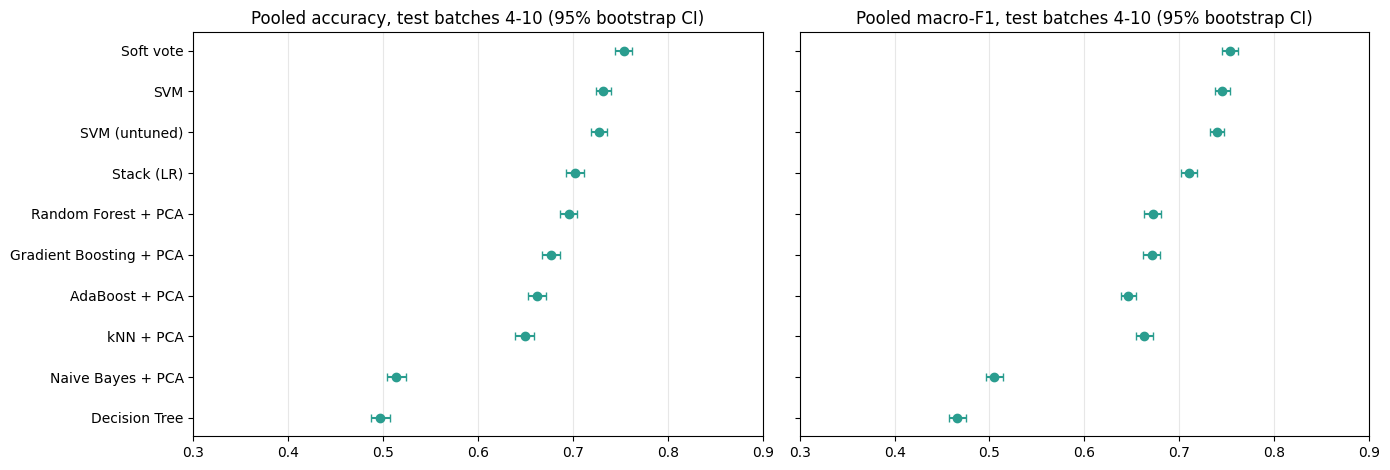

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
ordr = allres.index[::-1]
for ax, (col, lo, hi, title) in zip(axes, [("accuracy", "acc_low", "acc_high", "Pooled accuracy"),
                                         ("macro_f1", "f1_low", "f1_high", "Pooled macro-F1")]):
    v = allres.loc[ordr, col]
    ax.errorbar(v, range(len(ordr)), xerr=[v - allres.loc[ordr, lo], allres.loc[ordr, hi] - v],
                fmt="o", color="#2a9d8f", capsize=3)
    ax.set_yticks(range(len(ordr))); ax.set_yticklabels(ordr)
    ax.set_title(f"{title}, test batches 4-10 (95% bootstrap CI)"); ax.set_xlim(0.3, 0.9)
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../results/step10_pooled_ci.png", dpi=150)
plt.show()

**What to notice (pooled over all 8,881 test samples of batches 4-10; models trained on batches 1-3):**
- **Ranking by pooled accuracy:** soft vote 75.3%, tuned SVM 73.2%, untuned SVM 72.7%, stack 70.2%, Random Forest + PCA
  69.5%, Gradient Boosting + PCA 67.7%, AdaBoost + PCA 66.2%, kNN + PCA 64.9%, Naive Bayes + PCA 51.4%,
  Decision Tree 49.7%.
- **The intervals are about +/-1 point wide**, so the top group (soft vote, SVM) is separated from the Stack and
  the tree/kNN models, and the Decision Tree and Naive Bayes are far behind. The tuned and untuned SVM intervals
  overlap, so tuning did not make a clear difference.
- **Remember the caveat:** these intervals treat rows as independent, so the real uncertainty is larger.
- **Note on AdaBoost + PCA:** it appears here with its *tuned* setting (66.2%). The untuned default scored 71.2% in
  Step 7. Neither was chosen with test data (tuned settings come from the validation rule), so we keep the tuned one.

## 4. Per-batch accuracy and its uncertainty

In [6]:
per = res[res["group"].str.startswith("batch")].copy()
per["batch"] = per["group"].str.split().str[1].astype(int)
acc_tab = per.pivot(index="model", columns="batch", values="accuracy").loc[allres.index]
half_width = per.assign(hw=(per["acc_high"] - per["acc_low"]) / 2).pivot(index="model", columns="batch", values="hw").loc[allres.index]
print("Accuracy (%) per test batch")
(acc_tab * 100).round(1)

Accuracy (%) per test batch


batch,4,5,6,7,8,9,10
model,,,,,,,
Soft vote,80.1,98.5,84.7,78.4,83.3,92.7,61.8
SVM,88.2,94.4,90.0,82.2,83.3,82.1,49.6
SVM (untuned),87.6,95.4,87.1,81.2,58.7,94.6,51.7
Stack (LR),73.9,99.0,84.8,72.5,49.3,77.2,57.8
Random Forest + PCA,72.7,97.5,85.1,72.8,46.4,79.1,55.6
Gradient Boosting + PCA,72.7,97.0,75.3,71.3,55.4,70.7,58.0
AdaBoost + PCA,72.7,97.0,85.3,64.7,57.2,62.9,54.9
kNN + PCA,70.2,76.1,71.1,66.0,53.6,76.2,58.6
Naive Bayes + PCA,86.3,92.4,67.9,57.2,36.2,35.0,34.1


In [7]:
print("Half-width of the 95% CI (+/- percentage points) per test batch")
(half_width * 100).round(1)

Half-width of the 95% CI (+/- percentage points) per test batch


batch,4,5,6,7,8,9,10
model,,,,,,,
Soft vote,6.2,1.8,1.6,1.4,4.3,2.7,1.7
SVM,4.7,3.1,1.4,1.3,4.3,3.9,1.8
SVM (untuned),5.0,2.8,1.6,1.4,6.0,2.3,1.8
Stack (LR),6.8,1.3,1.6,1.6,5.8,4.3,1.8
Random Forest + PCA,6.8,2.3,1.6,1.5,5.8,4.2,1.8
Gradient Boosting + PCA,6.8,2.3,2.0,1.6,5.8,4.5,1.8
AdaBoost + PCA,6.8,2.3,1.6,1.7,6.0,4.9,1.8
kNN + PCA,7.1,6.1,2.1,1.7,6.0,4.3,1.8
Naive Bayes + PCA,5.3,3.6,2.2,1.7,5.6,4.7,1.7


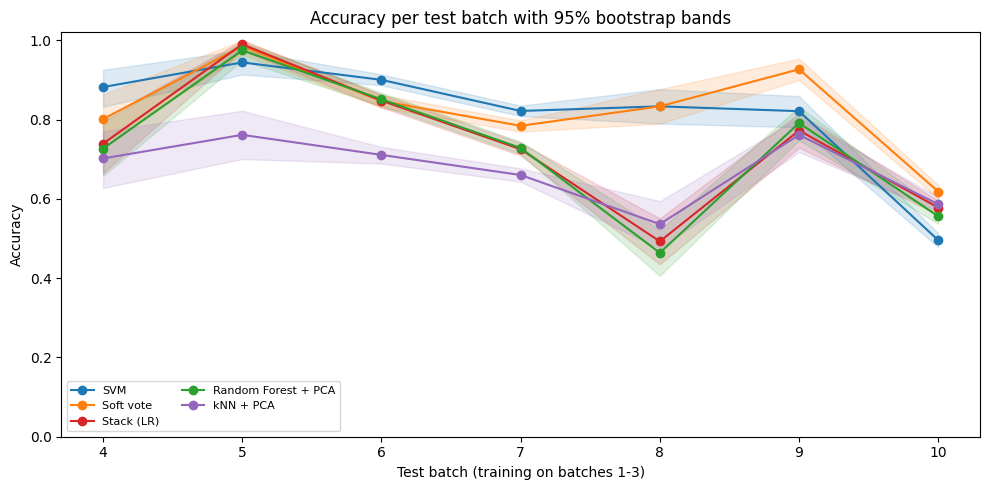

In [8]:
show = ["SVM", "Soft vote", "Stack (LR)", "Random Forest + PCA", "kNN + PCA"]
fig, ax = plt.subplots(figsize=(10, 5))
for k, c in zip(show, ["#1f77b4", "#ff7f0e", "#d62728", "#2ca02c", "#9467bd"]):
    d = per[per["model"] == k].sort_values("batch")
    ax.plot(d["batch"], d["accuracy"], marker="o", color=c, label=k)
    ax.fill_between(d["batch"], d["acc_low"], d["acc_high"], color=c, alpha=0.15)
ax.set_xlabel("Test batch (training on batches 1-3)"); ax.set_ylabel("Accuracy"); ax.set_ylim(0, 1.02)
ax.set_title("Accuracy per test batch with 95% bootstrap bands"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig("../results/step10_per_batch_ci.png", dpi=150)
plt.show()

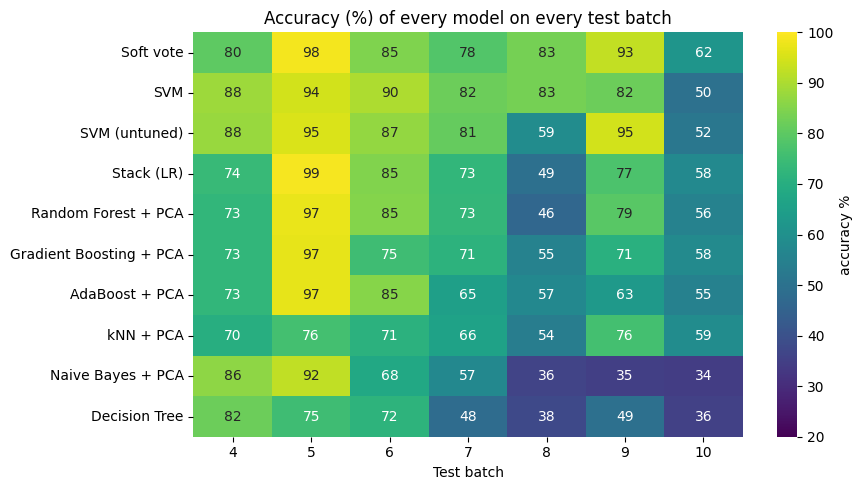

In [9]:
plt.figure(figsize=(9, 5))
sns.heatmap(acc_tab * 100, annot=True, fmt=".0f", cmap="viridis", vmin=20, vmax=100, cbar_kws={"label": "accuracy %"})
plt.xlabel("Test batch"); plt.ylabel("")
plt.title("Accuracy (%) of every model on every test batch")
plt.tight_layout()
plt.savefig("../results/step10_accuracy_heatmap.png", dpi=150)
plt.show()

**What to notice (per batch):**
- **Accuracy falls on later batches for every model, but not smoothly.** Batch 5 is easy (92-99% for most models) and
  batch 10 is hard for everyone (34-62%); no model reaches 62% there. The soft vote is best on batch 10 (61.8%),
  the tuned SVM is worst among the good models (49.6%).
- **The best model changes from batch to batch.** The tuned SVM is best on batches 4 (88.2%), 6 (90.0%) and 7 (82.2%), ties
  the soft vote on batch 8 (83.3%), and among the tuned models the soft vote is best on batches 9 (92.7%; the untuned SVM reaches 94.6%) and 10 (61.8%). The stack is highest
  on batch 5 (99.0%), which is within noise of the soft vote's 98.5%.
- **Tuning moved single batches a lot:** the tuned SVM gained 24.6 points on batch 8 (58.7% to 83.3%) but lost 12.5 on
  batch 9 (94.6% to 82.1%), compared with the untuned SVM.
- **Uncertainty depends on batch size:** on the big batches 6, 7 and 10 the intervals are about +/-1.3 to 2.2 points,
  but on batch 4 (161 samples) they are +/-4.7 to 7.1, on batch 8 (276 samples) +/-4.3 to 6.0, and on batch 9
  (369 samples) +/-2.3 to 5.0. Differences of a few points on these batches mean little.

## 5. Small batches (4 and 5) pooled

In [10]:
small = res[res["group"].isin(["4-5 (small)", "6-10"])].copy()
small_tab = small.pivot(index="model", columns="group", values="accuracy").loc[allres.index] * 100
small_hw = small.assign(hw=(small["acc_high"] - small["acc_low"]) / 2).pivot(index="model", columns="group", values="hw").loc[allres.index] * 100
pd.concat({"accuracy %": small_tab, "CI half-width (+/- points)": small_hw}, axis=1).round(1)

accuracy %       CI half-width (+/- points)     
group                   4-5 (small)  6-10                4-5 (small) 6-10
model                                                                    
Soft vote                      90.2  74.7                        3.1  0.9
SVM                            91.6  72.4                        2.9  0.9
SVM (untuned)                  91.9  71.9                        2.8  0.9
Stack (LR)                     87.7  69.4                        3.2  1.0
Random Forest + PCA            86.3  68.8                        3.4  0.9
Gradient Boosting + PCA        86.0  66.9                        3.5  1.0
AdaBoost + PCA                 86.0  65.4                        3.4  1.0
kNN + PCA                      73.5  64.5                        4.3  1.0
Naive Bayes + PCA              89.7  49.7                        3.1  1.0
Decision Tree                  78.2  48.5                        4.2  1.0

**How to read batches 4 and 5 (358 samples together):**
- Pooled, they give 73.5-91.9% accuracy with intervals of about +/-3 to 4 points, much wider than the +/-0.9 to 1.0
  points for the pooled batches 6-10.
- **They can mislead a model choice.** Naive Bayes + PCA scores 89.7% on batches 4-5 (about as good as the SVM at 91.6%)
  but only 49.7% on batches 6-10. A model judged only on these two small, early batches could look good and then
  fail later.
- Batch 4 has just 12 Ammonia and 12 Acetone samples, so per-gas results there are very noisy.
- **We therefore base conclusions on the pooled results and on the large batches (6, 7 and 10)** and treat
  batches 4 and 5 as indicative only.

## 6. Degradation with time: near batches (4-6) vs far batches (8-10)

In [11]:
near, far = [4, 5, 6], [8, 9, 10]
rows = []
for k in names:
    a_near, _ = analysis.metrics_from_confusion(sum(point[b][k] for b in near))
    a_far, _ = analysis.metrics_from_confusion(sum(point[b][k] for b in far))
    nb_, _ = analysis.metrics_from_confusion(analysis.pooled({b: boot[b][k] for b in near}, near))
    fb_, _ = analysis.metrics_from_confusion(analysis.pooled({b: boot[b][k] for b in far}, far))
    lo, hi = analysis.interval(fb_ - nb_)
    rows.append({"model": k, "near (4-6) %": a_near * 100, "far (8-10) %": a_far * 100,
                 "change (points)": (a_far - a_near) * 100, "CI low": lo * 100, "CI high": hi * 100})
nf = pd.DataFrame(rows).set_index("model").loc[allres.index]
nf.round(1).to_csv("../results/step10_near_far.csv")
nf.round(1)

,near (4-6) %,far (8-10) %,change (points),CI low,CI high
model,,,,,
Soft vote,85.6,66.6,-19.0,-21.1,-16.9
SVM,90.3,55.4,-34.9,-36.8,-32.9
SVM (untuned),87.9,56.5,-31.4,-33.3,-29.3
Stack (LR),85.3,59.1,-26.1,-28.2,-24.0
Random Forest + PCA,85.3,57.3,-28.0,-30.2,-25.9
Gradient Boosting + PCA,77.0,59.1,-17.9,-20.4,-15.5
AdaBoost + PCA,85.4,55.9,-29.6,-31.8,-27.4
kNN + PCA,71.5,60.0,-11.4,-13.8,-9.0
Naive Bayes + PCA,71.5,34.4,-37.1,-39.6,-34.8


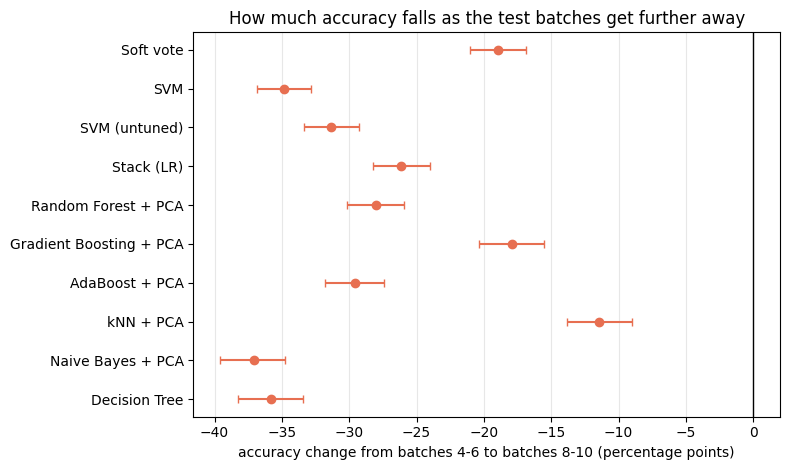

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.8))
d = nf.iloc[::-1]
ax.errorbar(d["change (points)"], range(len(d)), xerr=[d["change (points)"] - d["CI low"], d["CI high"] - d["change (points)"]],
            fmt="o", color="#e76f51", capsize=3)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(range(len(d))); ax.set_yticklabels(d.index)
ax.set_xlabel("accuracy change from batches 4-6 to batches 8-10 (percentage points)")
ax.set_title("How much accuracy falls as the test batches get further away")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../results/step10_near_far.png", dpi=150)
plt.show()

**What to notice (drop from batches 4-6 to batches 8-10; all drops are clearly below zero):**
- **The tuned SVM is best on near batches (90.3%) but falls the most among the good models:** -34.9 points
  (95% CI -36.8 to -32.9), to 55.4%.
- **The soft vote falls less:** -19.0 points (85.6% to 66.6%), and it has the best accuracy on the far batches (66.6%).
  The stack (59.1%) and Gradient Boosting + PCA (59.1%) follow; kNN + PCA has the smallest drop (-11.4) but only
  because it starts low (71.5%).
- **Decision Tree and Naive Bayes + PCA fall the most** (-35.8 and -37.1) and end at about 34-37%.
- **No model keeps more than 67% on the far batches.**
- **Caveat:** the gas mix also differs between these groups of batches (Step 2), so part of the drop may come from
  the mix of gases and not only from drift.

## 7. Which differences are real? Paired comparison with the tuned SVM (pooled, batches 4-10)

In [13]:
rows = []
acc_svm_b, _ = analysis.metrics_from_confusion(analysis.pooled({b: boot[b]["SVM"] for b in BATCHES}, BATCHES))
acc_svm, _ = analysis.metrics_from_confusion(sum(point[b]["SVM"] for b in BATCHES))
for k in names:
    if k == "SVM":
        continue
    a, _ = analysis.metrics_from_confusion(sum(point[b][k] for b in BATCHES))
    a_b, _ = analysis.metrics_from_confusion(analysis.pooled({b: boot[b][k] for b in BATCHES}, BATCHES))
    lo, hi = analysis.interval(a_b - acc_svm_b)
    verdict = "better" if lo > 0 else "worse" if hi < 0 else "not clearly different"
    rows.append({"model": k, "accuracy %": a * 100, "difference vs SVM (points)": (a - acc_svm) * 100,
                 "CI low": lo * 100, "CI high": hi * 100, "verdict": verdict})
paired = pd.DataFrame(rows).set_index("model").sort_values("difference vs SVM (points)", ascending=False)
paired.round(1).to_csv("../results/step10_paired_vs_svm.csv")
print(f"Tuned SVM pooled accuracy: {acc_svm * 100:.1f}%")
paired.round(1)

Tuned SVM pooled accuracy: 73.2%


,accuracy %,difference vs SVM (points),CI low,CI high,verdict
model,,,,,
Soft vote,75.3,2.1,1.1,3.1,better
SVM (untuned),72.7,-0.5,-1.1,0.2,not clearly different
Stack (LR),70.2,-3.0,-4.0,-2.2,worse
Random Forest + PCA,69.5,-3.7,-4.8,-2.6,worse
Gradient Boosting + PCA,67.7,-5.5,-6.6,-4.3,worse
AdaBoost + PCA,66.2,-7.0,-8.0,-5.9,worse
kNN + PCA,64.9,-8.3,-9.4,-7.3,worse
Naive Bayes + PCA,51.4,-21.8,-23.1,-20.6,worse
Decision Tree,49.7,-23.5,-24.7,-22.4,worse


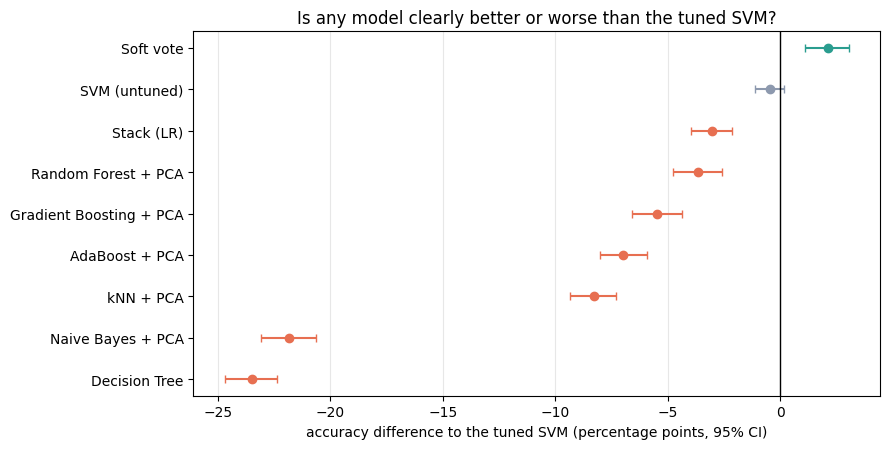

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.6))
d = paired.iloc[::-1]
col = d["verdict"].map({"better": "#2a9d8f", "worse": "#e76f51", "not clearly different": "#8d99ae"})
for i, (name, r) in enumerate(d.iterrows()):
    ax.errorbar(r["difference vs SVM (points)"], i, xerr=[[r["difference vs SVM (points)"] - r["CI low"]], [r["CI high"] - r["difference vs SVM (points)"]]],
                fmt="o", color=col[name], capsize=3)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(range(len(d))); ax.set_yticklabels(d.index)
ax.set_xlabel("accuracy difference to the tuned SVM (percentage points, 95% CI)")
ax.set_title("Is any model clearly better or worse than the tuned SVM?")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../results/step10_paired_vs_svm.png", dpi=150)
plt.show()

**What to notice (difference to the tuned SVM, pooled; same resampled rows for both models):**

| Model | Difference (points) | 95% CI | Verdict |
|---|---|---|---|
| Soft vote | +2.1 | [1.1, 3.1] | better (see caution below) |
| SVM (untuned) | -0.5 | [-1.1, 0.2] | not clearly different |
| Stack (LR) | -3.0 | [-4.0, -2.2] | worse |
| Random Forest + PCA | -3.7 | [-4.8, -2.6] | worse |
| Gradient Boosting + PCA | -5.5 | [-6.6, -4.3] | worse |
| AdaBoost + PCA | -7.0 | [-8.0, -5.9] | worse |
| kNN + PCA | -8.3 | [-9.4, -7.3] | worse |
| Naive Bayes + PCA | -21.8 | [-23.1, -20.6] | worse |
| Decision Tree | -23.5 | [-24.7, -22.4] | worse |

- **Tuning made no clear difference** to SVM pooled (-0.5 points, interval includes 0), even though single batches moved a lot.
- **The learned stack, and every other model except the soft vote, is clearly worse than the tuned SVM.**
- **Caution about the soft vote:** the interval excludes zero only if rows are independent, which they are not.
  Batch by batch, the soft vote beats the tuned SVM on 3 batches (5, 9, 10), loses on 3 (4, 6, 7) and ties on 1 (8).
  Its pooled advantage comes mainly from batch 10 (3,000 samples, 61.8% vs 49.6%). So we say it scored higher on this test
  set, mostly because of batch 10, and we do **not** claim it is generally better than SVM.

## 8. Confusion matrices: where do the errors happen?

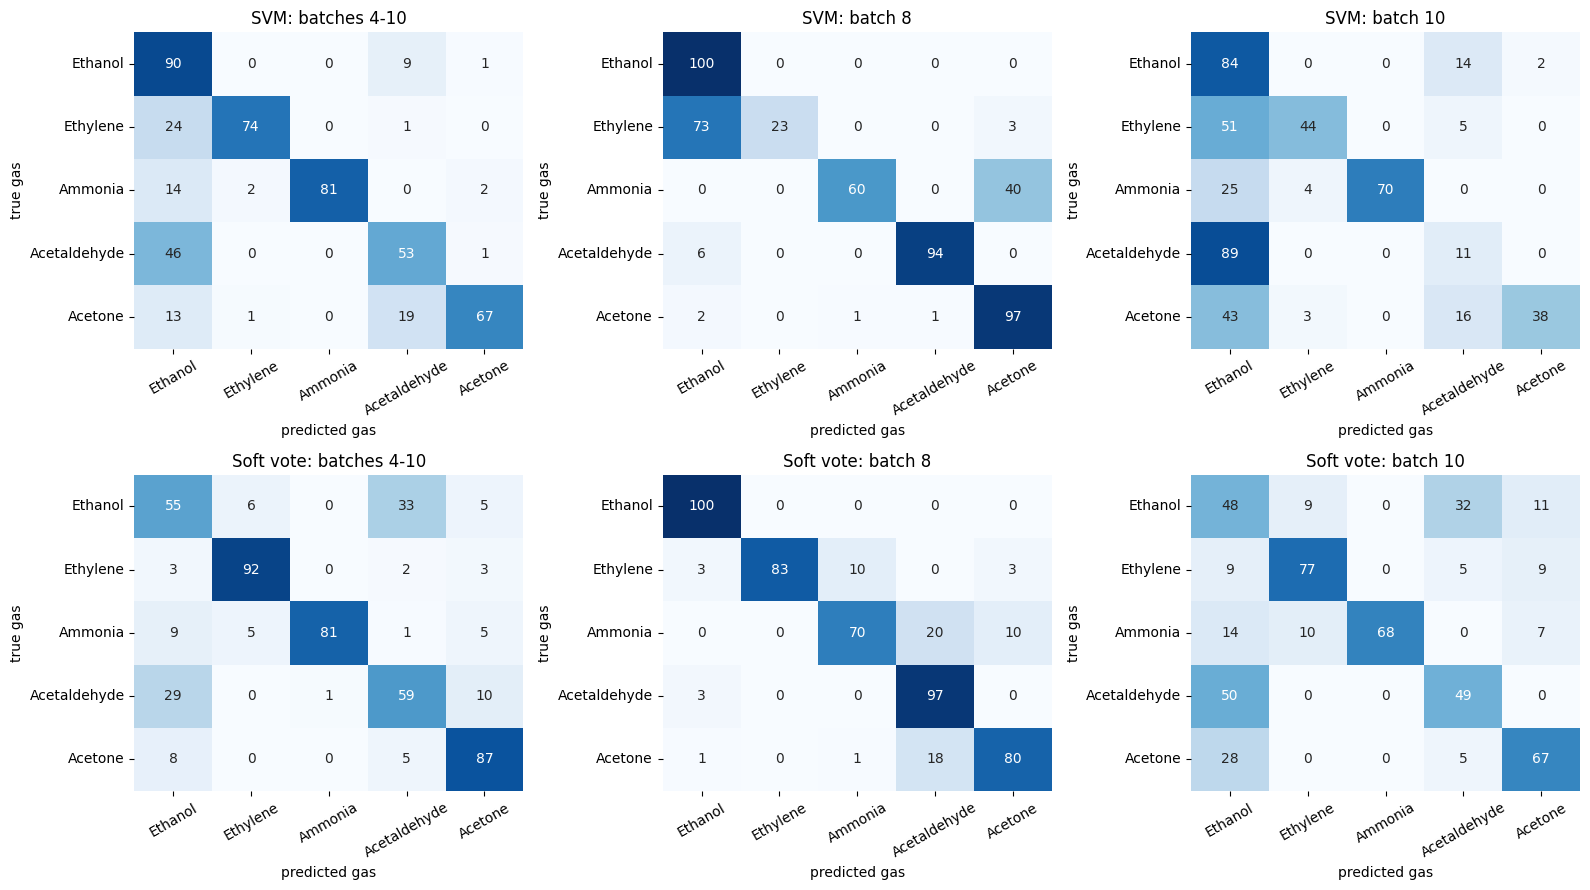

In [15]:
def cm_for(k, bs):
    return sum(point[b][k] for b in bs)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for r, k in enumerate(["SVM", "Soft vote"]):
    for c, (title, bs) in enumerate([("batches 4-10", BATCHES), ("batch 8", [8]), ("batch 10", [10])]):
        cm = cm_for(k, bs)
        pct = cm / cm.sum(axis=1, keepdims=True) * 100
        sns.heatmap(pct, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, xticklabels=GASES, yticklabels=GASES,
                    ax=axes[r, c], cbar=False)
        axes[r, c].set_title(f"{k}: {title}"); axes[r, c].set_xlabel("predicted gas"); axes[r, c].set_ylabel("true gas")
        axes[r, c].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("../results/step10_confusion_matrices.png", dpi=150)
plt.show()
pd.DataFrame(cm_for("SVM", BATCHES), index=GASES, columns=GASES).to_csv("../results/step10_confusion_svm_pooled_counts.csv")

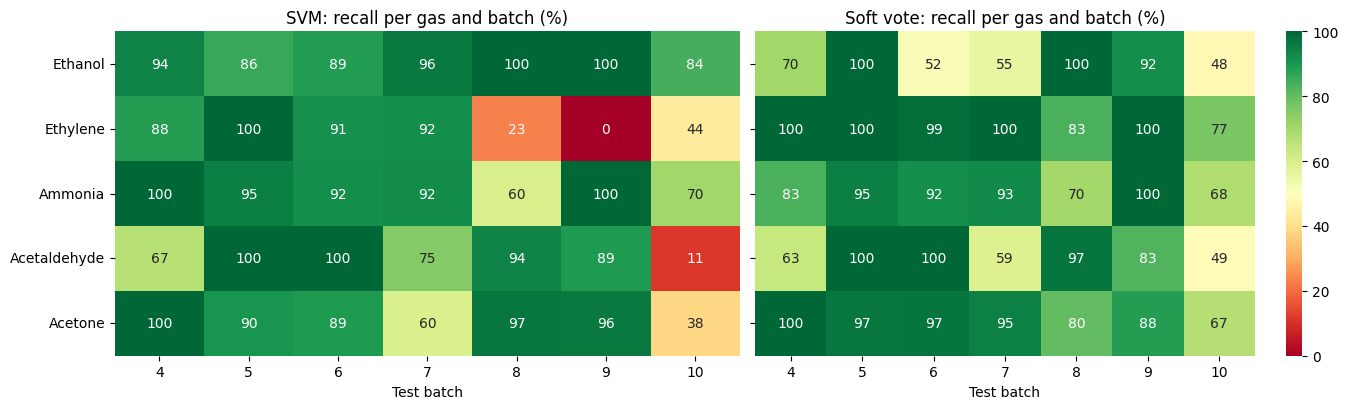

Samples per gas and batch (small counts make recall noisy):


batch,4,5,6,7,8,9,10
gas,,,,,,,
Ethanol,64,28,514,649,30,61,600
Ethylene,43,40,574,662,30,55,600
Ammonia,12,20,110,360,40,100,600
Acetaldehyde,30,46,29,744,33,75,600
Acetone,12,63,606,630,143,78,600


In [16]:
# recall of each gas in every test batch (how often the gas is found when it is really present)
def recall_table(k):
    rows = {}
    for b in BATCHES:
        cm = point[b][k]
        rows[b] = cm.diagonal() / cm.sum(axis=1)
    return pd.DataFrame(rows, index=GASES) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, k in zip(axes, ["SVM", "Soft vote"]):
    t = recall_table(k)
    sns.heatmap(t, annot=True, fmt=".0f", cmap="RdYlGn", vmin=0, vmax=100, ax=ax, cbar=(k == "Soft vote"))
    ax.set_title(f"{k}: recall per gas and batch (%)"); ax.set_xlabel("Test batch")
plt.tight_layout()
plt.savefig("../results/step10_gas_recall.png", dpi=150)
plt.show()
recall_table("SVM").round(1).to_csv("../results/step10_gas_recall_svm.csv")
nsamp = test.groupby(["batch", "gas"]).size().unstack()[GASES].T
print("Samples per gas and batch (small counts make recall noisy):")
nsamp

**What to notice (where the errors happen):**
- **The tuned SVM's mistakes mostly go to Ethanol.** Over batches 4-10, 46% of Acetaldehyde, 24% of Ethylene, 14% of
  Ammonia and 13% of Acetone samples are labelled Ethanol. On batch 10 it is worse: 89% of Acetaldehyde (600 samples),
  51% of Ethylene and 43% of Acetone become Ethanol.
- **Drift hits different gases in different batches** (recall heatmap): the SVM finds Ethylene 88-100% of the time on
  batches 4-7 but only 23% on batch 8, 0% on batch 9 and 44% on batch 10; Acetaldehyde falls to 11% on batch 10 and
  Acetone to 38%. This agrees with Step 3, where Ethylene had moved furthest from its training position in batches 8-9
  and Acetone in batch 10, although we did not prove that the two are linked. Ethylene on batches 8 and 9 has only 30 and
  55 samples, so those two recalls are noisy.
- **The soft vote makes different mistakes.** It keeps Ethylene recall at 77-100% on every batch, but loses Ethanol
  (55% pooled; 33% of Ethanol samples are called Acetaldehyde), and on batch 10 only 48% of Ethanol and 49% of
  Acetaldehyde are found (half of the Acetaldehyde samples are called Ethanol).
- **Ammonia is the most stable gas** for both models (81% pooled recall; 60-100% on every batch), which fits Step 3.
- No model solves batch 10: the best result is still wrong for more than a third of its samples.

## Summary of Step 10
- **Drift is large and uneven.** Accuracy falls from batches 4-6 to 8-10 for every model: the tuned SVM drops 34.9 points
  (90.3% to 55.4%), the soft vote 19.0 points (85.6% to 66.6%). No model exceeds 67% on the far batches, and batch 10
  is hard for all (34-62%).
- **Pooled over batches 4-10:** soft vote 75.3%, tuned SVM 73.2%, untuned SVM 72.7%, stack 70.2%, then the
  PCA-based tree models and kNN (65-70%), with Decision Tree and Naive Bayes + PCA far behind (about 50%).
- **Which differences are real:** the tuned SVM is clearly better than everything except the soft vote; tuning did not
  clearly change SVM (-0.5 points); the soft vote scores higher than SVM pooled (+2.1) but this is mostly batch 10
  (it wins 3 batches, loses 3, ties 1), so we do not claim a general win.
- **Errors are structured:** the SVM tends to call other gases Ethanol; Ethylene, Acetaldehyde and Acetone are hit
  hardest in the late batches, while Ammonia stays stable.
- **Limits:** intervals assume independent rows and are therefore too narrow; batches 4, 5, 8 and 9 are small; the gas
  mix differs between batches; one training split (batches 1-3); models trained once with fixed seeds (Step 12 adds
  repeated runs for the randomised models).